---
title: "Lecture 17: Central Limit Theorem, Strong Law of Large Numbers"
author: "Jamie Haddock"
format:
    revealjs:
        output-file: Lecture17_slides
        slide-number: true
        preview-links: auto
        logo: figs/hmc.png
        css: input/slides.css
        incremental: true
        smaller: true
        code-fold: true
        embed-resources: true
        html-math-method: katex
        slide-level: 3
    html:
        code-fold: true
        embed-resources: true
        output-file: Lecture17
        code-links:
          - text: "Open in Colab"
            href: "https://colab.research.google.com/github/jamiehadd/Math-151-Probability/blob/main/17_clt-slln.ipynb"
            icon: "laptop"
    pdf:
        documentclass: article
        toc: true
        number-sections: true
        output-file: Lecture17
        geometry:
          - top=1in
          - left=1in
          - bottom=1in
          - right=1in
format-links: false
jupyter: python3
colab:
  gh-user: "jamiehadd"
  gh-repo: "Math-151-Probability"
filters:
  - input/remove-pause.lua
  - colab
execute:
  echo: true
  eval: true
---

## Recap

Chernoff's bound requires the MGF to exist and be finite, which is stronger than assuming finite variance (Chebyshev) or mean (Markov), but yields a much stronger bound!

. . .

![](figs/summary_chernoff.jpeg){width="60%" fig-align="center"}

. . .

Now, we turn back to asymptotic convergence results for $\bar{X}_n$ and $Z_n$!

# Central Limit Theorem

What is the shape of the distribution of $Z_n = \dfrac{S_n - n\mu}{\sigma\sqrt{n}}$?

Recall: $E[Z_n] = 0$ and $\operatorname{Var}(Z_n) = 1$.

## Central Limit Theorem

::: {.callout-note title="Theorem (CLT)"}
Let $X_1, X_2, \dots$ be i.i.d. with mean $\mu$ and variance $\sigma^2$.  Define $Z_n = \frac{X_1 + \cdots + X_n - n\mu}{\sigma \sqrt{n}}$. Then the CDF of $Z_n$ converges to the standard normal CDF $\Phi(z)$,
$$\lim_{n \rightarrow \infty} P(Z_n \le z) = \Phi(z)$$
for every $z$.
:::

- Random effects are often the sum of a large number of small random factors (e.g., real-world noise), so this result has a wide array of applications!
- We don't need tedious PMFs/PDFs in this case, just the standard normal CDF $\Phi$!

## Central Limit Theorem

One way to prove this result is to show instead that the MGFs converge!

. . .

**Proof sketch.** Assume the MGF of $X_i$, $M_{X_i}$, exists near $0$. Since the $X_i$ are identically distributed, we have $M_{X_i}$ is the same for all $i$, call this $M_X$. (Without loss of generality, we take $\mu = 0$, $\sigma = 1$.)

1. By independence and linearity, with some work, we can show that the MGF of $Z_n$ is $\left[M_X(s/\sqrt{n})\right]^n.$

. . .

2. Since $E[X] = 0$ and $E[X^2] = 1$: the second order Taylor series expansion around $u = 0$ satisfies $M_X(u) = 1 + \dfrac{u^2}{2} + o(u^2)$.

. . .

3. So $\left[M_X(s/\sqrt{n})\right]^n = \left[1 + \dfrac{s^2}{2n} + o\!\left(\dfrac{1}{n}\right)\right]^n \to e^{s^2/2}$, the MGF of $N(0,1)$.

. . .

4. MGF convergence implies convergence of the CDFs. $\square$

## Convergence in Distribution

::: {.callout-note title="Definition"}
The sequence of random variable $Y_n$ **converges in distribution** to $Y$, $Y_n \to Y$, if $F_{Y_n}(y) \to F_Y(y)$ at every $y$ where $F_Y$ is continuous.
:::

- The CLT says $Z_n \to N(0,1)$ in distribution.

. . .

- Convergence in probability $\Rightarrow$ convergence in distribution.
- Convergence in distribution $\not\Rightarrow$ convergence in probability.

## Normal Approximation by CLT

Let $S_n = X_1 + \cdots + X_n$, where the $X_i$ are i.i.d. random variables with mean $\mu$ and variance $\sigma^2$.  If $n$ is large, the probability $P(S_n \le c)$ can be approximated by treating $S_n$ as if it were normal, according to the following process:

1. Calculate the mean $n\mu$ and the variance $n\sigma^2$ of $S_n$.
2. Calculate the normalized value $z = (c - n\mu)/\sigma \sqrt{n}$.
3. Use the approximation $$P(S_n \le c) = P(Z_n \le z) \approx \Phi(z).$$

### Example: polling, revisited

How many people must we poll so the estimate is within $\varepsilon = 0.01$ of $p$ with probability at least $0.95$?

We have $X_i \sim \text{Bernoulli}(p)$ i.i.d., so $\mu = p$ and $\sigma^2 = p(1-p) \le 1/4$. Since $p$ is unknown, use the worst case $\sigma = 1/2$ (a larger $\sigma$ means a larger required $n$).

. . .

**Rewrite the event in terms of $S_n$.** 
$$P(|\bar{X}_n - p| \ge \varepsilon) = P(|S_n - np| \ge n\varepsilon) \approx 2P(S_n \le np - n\varepsilon),$$
where the approximation follows from symmetry of the standard normal distribution.

---

**Step 1.** The mean of $S_n$ is $n\mu = np$ and its variance is $n\sigma^2$.

. . .

**Step 2.** Calculate the normalized value $z = (c - n\mu)/(\sigma\sqrt{n})$:

$c = n(p - \varepsilon)$: $\ z = \dfrac{-n\varepsilon}{\sigma\sqrt{n}} = -\dfrac{\varepsilon\sqrt{n}}{\sigma}$.

. . .

**Step 3.** Use the approximation $P(S_n \le c) \approx \Phi(z)$:

$P(S_n \le n(p-\varepsilon)) \approx \Phi\!\left(-\dfrac{\varepsilon\sqrt{n}}{\sigma}\right) = 1 - \Phi\!\left(\dfrac{\varepsilon\sqrt{n}}{\sigma}\right)$, by the symmetry of $\Phi$.

Adding the two tails,
$$P(|\bar{X}_n - p| \ge \varepsilon) \approx 2\left(1 - \Phi\!\left(\frac{\varepsilon\sqrt{n}}{\sigma}\right)\right).$$

---

**Solve for $n$.** We want this to be at most $0.05$:
$$2\left(1 - \Phi\!\left(\frac{\varepsilon\sqrt{n}}{\sigma}\right)\right) \le 0.05 \iff \Phi\!\left(\frac{\varepsilon\sqrt{n}}{\sigma}\right) \ge 0.975.$$


. . .

From the normal table, $\Phi(1.96) \approx 0.975$, so
$$\frac{\varepsilon\sqrt{n}}{\sigma} \ge 1.96 \iff n \ge \left(\frac{1.96\,\sigma}{\varepsilon}\right)^2 = \left(\frac{1.96 \cdot 0.5}{0.01}\right)^2 = 98^2 = 9604,$$
where we have assumed that the Bernoulli RVs have the worst case variance, $\sigma^2 = 1/4$.

. . .

Unlike Chebyshev and Chernoff, this is an *approximation* (it treats $S_n$ as exactly normal), not a guaranteed bound.

. . .

| Method | $n \ge$ |
|---|---|
| Chebyshev | 50,000 |
| Chernoff | 18,445 |
| CLT (approximation) | 9,604 |

### De Moivre–Laplace Approximation to Binomial

If $S_n \sim \text{Binomial}(n, p)$, then $\mu = np$, $\sigma^2 = np(1-p)$, and for large $n$, the previous process suggests that we should approximate
$$P(k \le S_n \le l) \approx \Phi\!\left(\frac{l - np}{\sqrt{np(1-p)}}\right) - \Phi\!\left(\frac{k - np}{\sqrt{np(1-p)}}\right).$$

. . .

However, when if we want to estimate $P(S_n = k)$ using $k=l$, this is a very bad estimate!  Why?

. . .

![](figs/demoivre_laplace.png)

---

::: {.callout-note title="De Moivre–Laplace approximation"}
If $S_n \sim \text{Binomial}(n, p)$, $n$ is large, and $k$ and $l$ are nonnegative integers, then
$$P(k \le S_n \le l) \approx \Phi\!\left(\frac{l + \tfrac{1}{2} - np}{\sqrt{np(1-p)}}\right) - \Phi\!\left(\frac{k - \tfrac{1}{2} - np}{\sqrt{np(1-p)}}\right).$$
:::

. . .

The $\tfrac{1}{2}$ is called a *continuity correction*: it accounts for approximating a discrete distribution by a continuous one.

## Summary

The CLT tells us that $Z_n \to N(0,1)$ in distribution.

![](figs/summary_clt.jpeg){fig-align="center"}

# Strong Law of Large Numbers

Now, we turn back to $\bar{X}_n$ and seek to say something stronger than the WLLN.  

. . .

The WLLN says that the probability of a significant deviation of $\bar{X}_n$ away from $\mu$ goes to 0 as $n \rightarrow \infty$. But, at each $n$, a bad event $\{|\bar{X}_n - \mu| \ge \varepsilon\}$ could happen as long as you run enough trials that you expect to see this very small probability event!

---

No matter how far right you move in the plot below, if you run many many trials, the WLLN does not guarantee that one of the lines will not pop out of the gray bar.

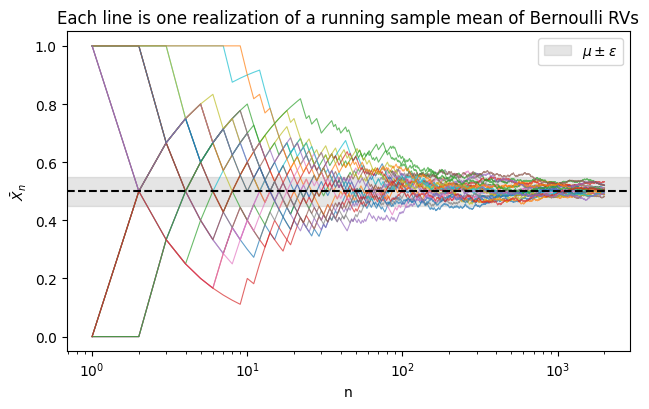

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(151)

p, eps = 0.5, 0.05
paths, N = 25, 2000
ns = np.arange(1, N + 1)

X = rng.binomial(1, p, size=(paths, N))
xbar = np.cumsum(X, axis=1) / ns                  # row = one realization of X̄_1, ..., X̄_N

plt.figure(figsize=(6.5, 4.2))
for i in range(paths):
    plt.plot(ns, xbar[i], lw=0.8, alpha=0.7)
plt.axhline(p, color="k", ls="--")
plt.axhspan(p - eps, p + eps, color="gray", alpha=0.2, label=r"$\mu \pm \varepsilon$")
plt.xscale("log")
plt.xlabel("n")
plt.ylabel(r"$\bar{X}_n$")
plt.title("Each line is one realization of a running sample mean of Bernoulli RVs")
plt.legend()
plt.tight_layout()
plt.show()

## SLLN

::: {.callout-note title="Theorem (SLLN)"}
Let $X_1, X_2, \dots$ be i.i.d. with mean $\mu$. Then the sequence of sample means converges to $\mu$ with probability 1, $$P\!\left(\lim_{n \to \infty} \bar{X}_n = \mu\right) = 1.$$
:::

. . .

**Interpretation.** With probability $1$, a single infinite running sample mean has the following property: for any $\epsilon > 0$, there is an $n_0$ (which depends on the run and on $\epsilon$) such that for all $n \ge n_0$, the running sample mean stays within $\epsilon$ of $\mu$, $|\bar{X}_n - \mu| < \epsilon$.

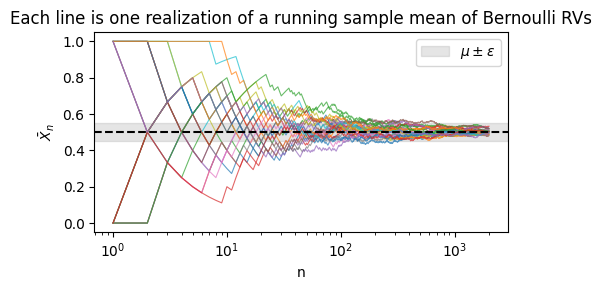

In [2]:
#| echo: false

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(151)

p, eps = 0.5, 0.05
paths, N = 25, 2000
ns = np.arange(1, N + 1)

X = rng.binomial(1, p, size=(paths, N))
xbar = np.cumsum(X, axis=1) / ns                  # row = one realization of X̄_1, ..., X̄_N

plt.figure(figsize=(5, 3))
for i in range(paths):
    plt.plot(ns, xbar[i], lw=0.8, alpha=0.7)
plt.axhline(p, color="k", ls="--")
plt.axhspan(p - eps, p + eps, color="gray", alpha=0.2, label=r"$\mu \pm \varepsilon$")
plt.xscale("log")
plt.xlabel("n")
plt.ylabel(r"$\bar{X}_n$")
plt.title("Each line is one realization of a running sample mean of Bernoulli RVs")
plt.legend()
plt.tight_layout()
plt.show()


---

**Relationship between SLLN and WLLN.**

- SLLN $\Rightarrow$ WLLN.
- WLLN controls the set of $\bar{X}_n$ at each $n$ separately; SLLN controls the whole sequence (for all $n$) at once.

## Almost Sure Convergence

::: {.callout-note title="Definition"}
Let $c$ be a real number.  The sequence of random variables **$Y_1, Y_2, \cdots$ converges to $c$ almost surely** if $P\!\left(\lim_{n \to \infty} Y_n = c\right) = 1$.
:::

. . .

$$\text{almost sure conv.} \;\Longrightarrow\; \text{conv. in probability} \;\Longrightarrow\; \text{conv. in distribution}.$$

- converses are not true!
- SLLN: $\bar{X}_n \to \mu$ almost surely. 

### Example: minimum of uniform RVs

Let $U_1, U_2, \dots$ be i.i.d. $\text{Uniform}(0,1)$ and $Y_n = \min(U_1, \dots, U_n)$.

. . .

In any running trial, $Y_n \ge 0$ is monotonic nonincreasing with $n$ and $\ge 0$, so it must have a limit, $Y_n \to Y$.

. . .

For $0 < \epsilon \le 1$, we have
$$P(Y \ge \epsilon) \le P(U_1 \le \epsilon, \cdots, U_n \le \epsilon) = (1-\epsilon)^n$$
for all $n$.  Thus, $P(Y \ge \epsilon) \le \lim_{n \rightarrow \infty}(1-\epsilon)^n = 0$.

. . .

Thus, $P(Y=0) = 1$, and so $Y_n$ converges to 0 *almost surely*!


## Summary

The SLLN tells us that $\bar{X}_n \to \mu$ almost surely.

![](figs/summary_slln.jpeg){fig-align="center"}